In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

ERROR! Session/line number was not unique in database. History logging moved to new session 12


In [3]:
sns.set_theme(style="whitegrid", context="notebook")

In [4]:
csv_file = "DonorInformation-2.csv"

In [5]:
features = pd.read_csv(csv_file)
print(features)

      donor_id        name    age sex apo_e4_allele  education_years  \
0    326765665  H14.09.078     87   M             N               16   
1    326765656  H14.09.069  95-99   M             N               17   
2    326765654  H14.09.067     85   M             Y               10   
3    467056391  H15.09.103  90-94   F             N               11   
4    309335447  H14.09.010   100+   M             Y               16   
..         ...         ...    ...  ..           ...              ...   
102  309335458  H14.09.021     88   M             N               12   
103  309335462  H14.09.025     84   M             N               16   
104  309335454  H14.09.017     79   M             N               16   
105  309335486  H14.09.049  95-99   M             N               21   
106  309335442  H14.09.005  90-94   F             Y               14   

     age_at_first_tbi longest_loc_duration  cerad  num_tbi_w_loc  \
0                   0       Unknown or N/A      0              0   

In [6]:
nia_map = {
    0: "No AD pathological likelihood",
    1: "Low likelihood",
    2: "Intermediate likelihood",
    3: "High likelihood",
}

cerad_map = {
    0: "None",
    1: "Sparse",
    2: "Moderate",
    3: "Frequent",
}

features["nia_reagan_label"] = features["nia_reagan"].map(nia_map)
features["cerad_label"] = features["cerad"].map(cerad_map)

features[["nia_reagan","nia_reagan_label","cerad","cerad_label"]].head()

,nia_reagan,nia_reagan_label,cerad,cerad_label
0,1,Low likelihood,0,None
1,2,Intermediate likelihood,2,Moderate
2,2,Intermediate likelihood,3,Frequent
3,0,No AD pathological likelihood,0,None
4,2,Intermediate likelihood,3,Frequent


In [7]:
 print(features.head())

    donor_id        name    age sex apo_e4_allele  education_years  \
0  326765665  H14.09.078     87   M             N               16   
1  326765656  H14.09.069  95-99   M             N               17   
2  326765654  H14.09.067     85   M             Y               10   
3  467056391  H15.09.103  90-94   F             N               11   
4  309335447  H14.09.010   100+   M             Y               16   

   age_at_first_tbi longest_loc_duration  cerad  num_tbi_w_loc  ...  \
0                 0       Unknown or N/A      0              0  ...   
1                12              1-2 min      2              1  ...   
2                72             < 10 sec      3              1  ...   
3                87             < 10 sec      0              1  ...   
4                 0       Unknown or N/A      3              0  ...   

  control_set         nincds_arda_diagnosis ever_tbi_w_loc   race  \
0          31                   No Dementia              N  White   
1          26 

In [8]:
def set_primary_group(row):
    nia = row["nia_reagan"]
    dementia = row["act_demented"]
    if nia in [2, 3] and dementia == "No Dementia":
        return "Resilience-like"
    elif nia in [2, 3] and dementia == "Dementia":
        return "Pathology-positive dementia"
    elif nia in [0, 1] and dementia == "No Dementia":
        return "Low-pathology reference"
    elif nia in [0, 1] and dementia == "Dementia":
        return "Low-pathology dementia"
    else:
        return None
features["primary_group"] = features.apply(set_primary_group, axis=1)

features["primary_group"].value_counts()

primary_group
Low-pathology reference        36
Pathology-positive dementia    31
Resilience-like                21
Low-pathology dementia         19
Name: count, dtype: int64

In [9]:
for group_name, group_data in features.groupby("primary_group"):
    print(f" GROUP: {group_name} (Total: {len(group_data)})")
    for index, row in group_data.iterrows():
        print(f" - {row["name"]} (ID: {row["donor_id"]})")

 GROUP: Low-pathology dementia (Total: 19)
 - H14.09.061 (ID: 326765648)
 - H15.09.110 (ID: 467056409)
 - H14.09.047 (ID: 309335484)
 - H14.09.054 (ID: 309335491)
 - H14.09.082 (ID: 326765669)
 - H14.09.066 (ID: 326765653)
 - H14.09.002 (ID: 309335439)
 - H14.09.099 (ID: 326765686)
 - H14.09.022 (ID: 309335459)
 - H14.09.013 (ID: 309335450)
 - H14.09.073 (ID: 326765660)
 - H14.09.012 (ID: 309335449)
 - H14.09.059 (ID: 309335496)
 - H14.09.018 (ID: 309335455)
 - H14.09.043 (ID: 309335480)
 - H14.09.048 (ID: 309335485)
 - H14.09.064 (ID: 326765651)
 - H14.09.021 (ID: 309335458)
 - H14.09.025 (ID: 309335462)
 GROUP: Low-pathology reference (Total: 36)
 - H14.09.078 (ID: 326765665)
 - H15.09.103 (ID: 467056391)
 - H14.09.094 (ID: 326765681)
 - H14.09.070 (ID: 326765657)
 - H14.09.006 (ID: 309335443)
 - H14.09.074 (ID: 326765661)
 - H14.09.072 (ID: 326765659)
 - H14.09.015 (ID: 309335452)
 - H14.09.051 (ID: 309335488)
 - H14.09.038 (ID: 309335475)
 - H14.09.083 (ID: 326765670)
 - H14.09.077

In [10]:
def set_strict_group(row):
    braak = row["braak"]
    cerad = row["cerad"]
    dementia = row["act_demented"]
    if braak in [5,6] and cerad in [2,3] and dementia == "No Dementia":
        return "Strict resilience-like"
    elif braak in [5,6] and cerad in [2,3] and dementia == "Dementia":
        return "Strict pathology-positive dementia"
    else:
        return None
features["strict_group"] = features.apply(set_strict_group, axis=1)

features["strict_group"].value_counts()

strict_group
Strict pathology-positive dementia    22
Strict resilience-like                 6
Name: count, dtype: int64

In [11]:
summary_table = features.groupby('strict_group').agg(
    Donor_Count=('donor_id', 'count'),
    Braak_Mean=('braak','mean'),
    Braak_Median=('braak','median'),
    CERAD_Mean=('cerad','mean'),
    CERAD_Median=('cerad','median'),
).reset_index()

print("\n\nTOTAL NUMBER OF DONORS")
counts_df = features['strict_group'].value_counts().reset_index()
counts_df.columns = ['Strict Group','Donor Count']

display(counts_df)

donors_total = features['strict_group'].count()
print(f"Total Donors in Strict Group: {donors_total}")

print("\n\n--- SUMMARY STATISTICS ---")
display(summary_table)
print("\n--- BRAAK STAGE DISTRIBUTION ---")
display(pd.crosstab(features["strict_group"], features['braak'], margins=True))
print("\n--- CERAD STAGE DISTRIBUTION ---")

display(pd.crosstab(features['strict_group'], features['cerad'], margins=True))
                    
summary_table.to_csv('Strict_Group_Summary_Table.csv', index=False)



TOTAL NUMBER OF DONORS


,Strict Group,Donor Count
0,Strict pathology-positive dementia,22
1,Strict resilience-like,6


Total Donors in Strict Group: 28


--- SUMMARY STATISTICS ---


,strict_group,Donor_Count,Braak_Mean,Braak_Median,CERAD_Mean,CERAD_Median
0,Strict pathology-positive dementia,22,5.590909,6.0,2.727273,3.0
1,Strict resilience-like,6,5.333333,5.0,2.500000,2.5



--- BRAAK STAGE DISTRIBUTION ---


braak,5,6,All
strict_group,,,
Strict pathology-positive dementia,9,13,22
Strict resilience-like,4,2,6
All,13,15,28



--- CERAD STAGE DISTRIBUTION ---


cerad,2,3,All
strict_group,,,
Strict pathology-positive dementia,6,16,22
Strict resilience-like,3,3,6
All,9,19,28


In [12]:
summary_table = features.groupby('primary_group').agg(
    Donor_Count=('donor_id', 'count'),
    Braak_Mean=('braak','mean'),
    Braak_Median=('braak','median'),
    CERAD_Mean=('cerad','mean'),
    CERAD_Median=('cerad','median'),
).reset_index()

print("\n\nTOTAL NUMBER OF DONORS")
counts_df = features['primary_group'].value_counts().reset_index()
counts_df.columns = ['Strict Group','Donor Count']

display(counts_df)

donors_total = features['primary_group'].count()
print(f"Total Donors in Strict Group: {donors_total}")

print("\n\n--- SUMMARY STATISTICS ---")
display(summary_table)
print("\n--- BRAAK STAGE DISTRIBUTION ---")
display(pd.crosstab(features["primary_group"], features['braak'], margins=True))
print("\n--- CERAD STAGE DISTRIBUTION ---")

display(pd.crosstab(features['primary_group'], features['cerad'], margins=True))
                    
summary_table.to_csv('Primary_Group_Summary_Table.csv', index=False)



TOTAL NUMBER OF DONORS


,Strict Group,Donor Count
0,Low-pathology reference,36
1,Pathology-positive dementia,31
2,Resilience-like,21
3,Low-pathology dementia,19


Total Donors in Strict Group: 107


--- SUMMARY STATISTICS ---


,primary_group,Donor_Count,Braak_Mean,Braak_Median,CERAD_Mean,CERAD_Median
0,Low-pathology dementia,19,2.315789,3.0,0.473684,0.0
1,Low-pathology reference,36,2.305556,2.0,0.694444,1.0
2,Pathology-positive dementia,31,5.193548,5.0,2.548387,3.0
3,Resilience-like,21,3.714286,3.0,2.142857,2.0



--- BRAAK STAGE DISTRIBUTION ---


braak,0,1,2,3,4,5,6,All
primary_group,,,,,,,,
Low-pathology dementia,2,3,4,7,3,0,0,19
Low-pathology reference,2,8,9,11,6,0,0,36
Pathology-positive dementia,0,0,0,1,6,10,14,31
Resilience-like,0,3,0,8,2,5,3,21
All,4,14,13,27,17,15,17,107



--- CERAD STAGE DISTRIBUTION ---


cerad,0,1,2,3,All
primary_group,,,,,
Low-pathology dementia,12,5,2,0,19
Low-pathology reference,11,25,0,0,36
Pathology-positive dementia,0,2,10,19,31
Resilience-like,1,1,13,6,21
All,24,33,25,25,107


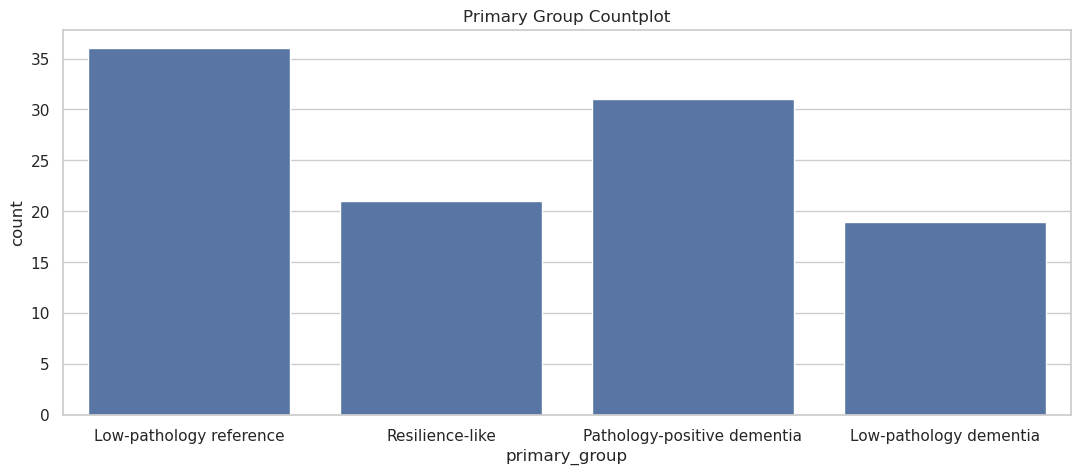

In [13]:
primary_group = "primary_group"
plt.figure(figsize=(13, 5))
sns.countplot(data=features, x = primary_group)
plt.title("Primary Group Countplot")
plt.show()


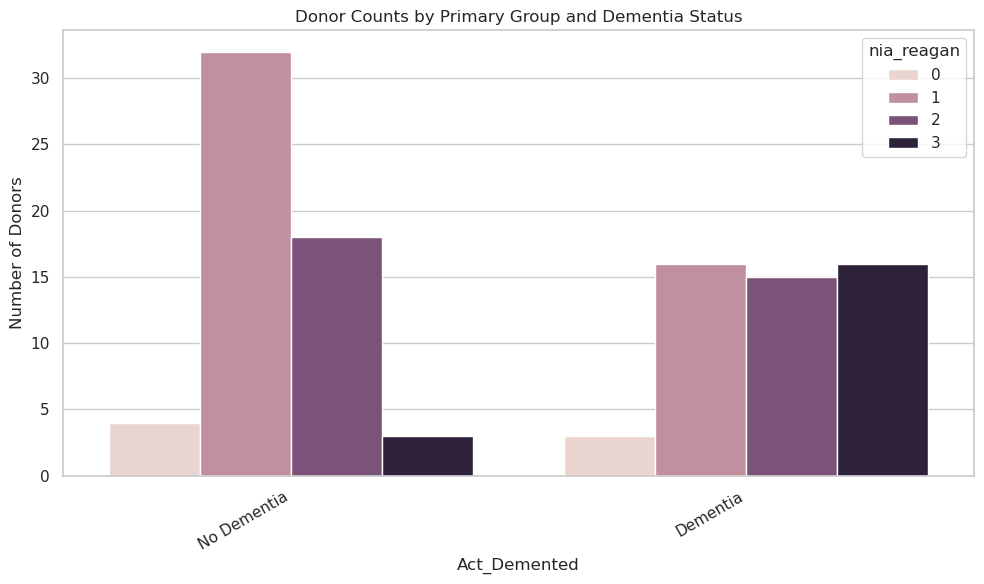

In [14]:
plt.figure(figsize=(10, 6))

sns.countplot(
data=features,
    x= 'act_demented',
    hue='nia_reagan'
)
plt.title("Donor Counts by Primary Group and Dementia Status")
plt.xlabel("Act_Demented")
plt.ylabel("Number of Donors")
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [15]:
features["resilience_combined"] = np.where(
    (features['primary_group'] == 'Resilience-like') |
    (features['strict_group'] == 'Strict resilience-like'),
    'Cognitive-Resilient Group',
    features['primary_group']
)
print("\n\nTOTAL NUMBER OF DONORS")
counts_df = features['resilience_combined'].value_counts().reset_index()

counts_df.columns = ['resilience_combined','Donor Count']

display(counts_df)

donors_total = features["resilience_combined"].count()
print(donors_total)



TOTAL NUMBER OF DONORS


,resilience_combined,Donor Count
0,Low-pathology reference,36
1,Pathology-positive dementia,31
2,Cognitive-Resilient Group,21
3,Low-pathology dementia,19


107


In [16]:
primary_dementia_groups = ["Pathology-positive dementia" , "Low-pathology dementia"]

strict_dementia_groups = ["Strict pathology-positive dementia"]
features["Dementia Group"] = np.where(
features["primary_group"].isin(primary_dementia_groups) |
features["strict_group"].isin(strict_dementia_groups),
    "Dementia Group",
    features["primary_group"]
)
print("\n\nTOTAL NUMBER OF DONORS"
counts_df = features['Dementia Group'].value_counts().reset_index()
counts_df.columns = ['Dementia Group','Donor Count']
display(counts_df)
donors_total = features["Dementia Group"].count()
print(donors_total)



TOTAL NUMBER OF DONORS


,Dementia Group,Donor Count
0,Dementia Group,50
1,Low-pathology reference,36
2,Resilience-like,21


107


Successfully saved file to: /home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/Cognitive_Resilienet_Group_CERAD_vs_Braak_Heatmap.pdf


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/Cognitive_Resilienet_Group_CERAD_vs_Braak_Heatmap.pdf

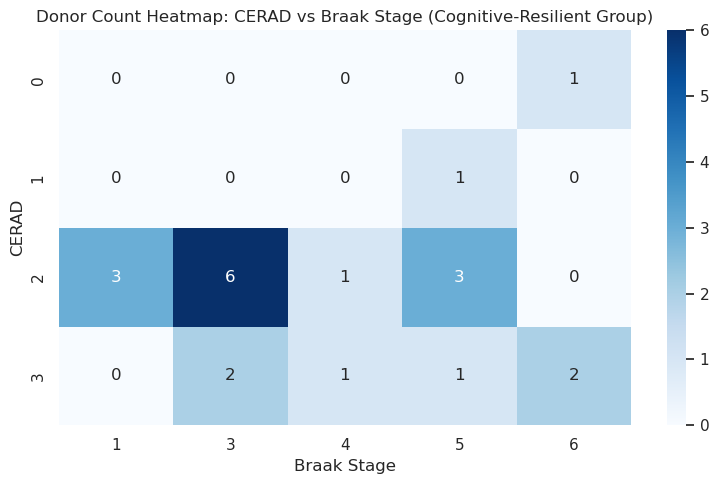

In [25]:
resilient_features = features[features['resilience_combined'] == 'Cognitive-Resilient Group']
    
ct_table = pd.crosstab(resilient_features['cerad'], resilient_features['braak'])
plt.figure(figsize=(8, 5))
sns.heatmap(
    ct_table,
    annot=True,
    fmt='d',
    cmap='Blues'
)
plt.title("Donor Count Heatmap: CERAD vs Braak Stage (Cognitive-Resilient Group)")
plt.xlabel("Braak Stage")
plt.ylabel("CERAD")
plt.xticks(rotation=0)
plt.tight_layout()
filenam = "Cognitive_Resilienet_Group_CERAD_vs_Braak_Heatmap.pdf"
plt.savefig(filename, format="pdf", bbox_inches="tight")

print(f"Successfully saved file to: {os.path.abspath(filenam)}")
display(FileLink(filenam))

plt.show()


Successfully saved file to: /home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/Pathology_Positive_Dementia_CERAD_vs_Braak_Heatmap.pdf


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/Pathology_Positive_Dementia_CERAD_vs_Braak_Heatmap.pdf

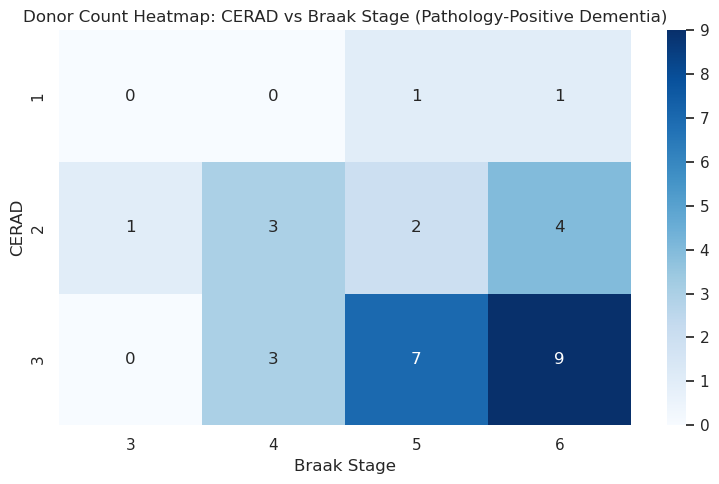

In [27]:
from IPython.display import FileLink, display

dementia_features = features[features["primary_group"] == "Pathology-positive dementia"]


ct_table = pd.crosstab(dementia_features["cerad"], dementia_features["braak"])


plt.figure(figsize=(8, 5))
sns.heatmap(ct_table, annot=True, fmt="d", cmap="Blues")

plt.title(
    "Donor Count Heatmap: CERAD vs Braak Stage (Pathology-Positive Dementia)"
)
plt.xlabel("Braak Stage")
plt.ylabel("CERAD")
plt.xticks(rotation=0)
plt.tight_layout()


filename = "Pathology_Positive_Dementia_CERAD_vs_Braak_Heatmap.pdf"


plt.savefig(filename, format="pdf", bbox_inches="tight")


print(f"Successfully saved file to: {os.path.abspath(filename)}")
display(FileLink(filename))


plt.show()

In [37]:
csv_file = "DonorInformation-2.csv"
features = pd.read_csv(csv_file)


def set_primary_group(row):
    nia = row["nia_reagan"]
    dementia = row["act_demented"]
    
    if nia in [2, 3] and dementia == "No Dementia":
        return "Resilience-like"
    elif nia in [2, 3] and dementia == "Dementia":
        return "Pathology-positive dementia"
    elif nia in [0, 1] and dementia == "No Dementia":
        return "Low-pathology reference"
    elif nia in [0, 1] and dementia == "Dementia":
        return "Low-pathology dementia"
    else:
        return None


def set_strict_group(row):
    braak = row["braak"]
    cerad = row["cerad"]
    dementia = row["act_demented"]
    
    if braak in [5, 6] and cerad in [2, 3] and dementia == "No Dementia":
        return "Strict resilience-like"
    elif braak in [5, 6] and cerad in [2, 3] and dementia == "Dementia":
        return "Strict pathology-positive dementia"
    else:
        return "Not Strict"


features["primary_group"] = features.apply(set_primary_group, axis=1)
features["strict_group"] = features.apply(set_strict_group, axis=1)


print("--- PRIMARY GROUP COUNTS ---")
print(features["primary_group"].value_counts())

print("\n--- STRICT GROUP COUNTS ---")
print(features["strict_group"].value_counts())


output_preview = features[["donor_id", "name", "act_demented", "nia_reagan", "braak", "cerad", "primary_group", "strict_group"]]
display(output_preview.head(10))


features.to_csv("Donor_Group_Classifications.csv", index=False)
features.to_excel("Donor_Group_Classifications.xlsx", index=False)

print("Finished processing and saved to both CSV and Excel!")

from IPython.display import FileLink, display

display(FileLink("Donor_Group_Classifications.xlsx"))

--- PRIMARY GROUP COUNTS ---
primary_group
Low-pathology reference        36
Pathology-positive dementia    31
Resilience-like                21
Low-pathology dementia         19
Name: count, dtype: int64

--- STRICT GROUP COUNTS ---
strict_group
Not Strict                            79
Strict pathology-positive dementia    22
Strict resilience-like                 6
Name: count, dtype: int64


,donor_id,name,act_demented,nia_reagan,braak,cerad,primary_group,strict_group
0,326765665,H14.09.078,No Dementia,1,1,0,Low-pathology reference,Not Strict
1,326765656,H14.09.069,No Dementia,2,5,2,Resilience-like,Strict resilience-like
2,326765654,H14.09.067,Dementia,2,4,3,Pathology-positive dementia,Not Strict
3,467056391,H15.09.103,No Dementia,0,4,0,Low-pathology reference,Not Strict
4,309335447,H14.09.010,Dementia,2,4,3,Pathology-positive dementia,Not Strict
5,309335457,H14.09.020,No Dementia,2,3,2,Resilience-like,Not Strict
6,326765676,H14.09.089,Dementia,3,6,3,Pathology-positive dementia,Strict pathology-positive dementia
7,326765681,H14.09.094,No Dementia,1,2,1,Low-pathology reference,Not Strict
8,326765648,H14.09.061,Dementia,1,2,1,Low-pathology dementia,Not Strict
9,326765657,H14.09.070,No Dementia,1,2,0,Low-pathology reference,Not Strict


Finished processing and saved to both CSV and Excel!


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/Donor_Group_Classifications.xlsx

In [38]:

from IPython.display import FileLink, display

csv_file = "DonorInformation-2.csv"
features = pd.read_csv(csv_file)


def set_resilient_group(row):
    nia = row["nia_reagan"]
    braak = row["braak"]
    cerad = row["cerad"]
    dementia = row["act_demented"]
    
    if nia in [2, 3] and dementia == "No Dementia":
        return "Resilience-like"
    elif braak in [5, 6] and cerad in [2, 3] and dementia == "No Dementia":
        return "Strict resilience-like group"
    else:
        return None


def set_dementia_group(row):
    nia = row["nia_reagan"]
    braak = row["braak"]
    cerad = row["cerad"]
    dementia = row["act_demented"]
    
    if nia in [2, 3] and dementia == "Dementia":
        return "Pathology-positive dementia"
    elif braak in [5, 6] and cerad in [2, 3] and dementia == "Dementia":
        return "Strict pathology-positive dementia"
    elif nia in [0, 1] and dementia == "Dementia":
        return "Low-pathology dementia"
    else:
        return "No Dementia"


features["Resilient Group"] = features.apply(set_resilient_group, axis=1)
features["Dementia Group"] = features.apply(set_dementia_group, axis=1)


output_table = features[["donor_id", "name", "act_demented", "nia_reagan", "braak", "cerad", "Resilient Group", "Dementia Group"]]
display(output_table)

features.to_excel("Donor_Group_StuperClassifications.xlsx", index=False)
features.to_csv("Donor_Group_StuperClassifications.csv", index=False)


display(FileLink("Donor_Group_StuperClassifications.xlsx"))

,donor_id,name,act_demented,nia_reagan,braak,cerad,Resilient Group,Dementia Group
0,326765665,H14.09.078,No Dementia,1,1,0,None,No Dementia
1,326765656,H14.09.069,No Dementia,2,5,2,Resilience-like,No Dementia
2,326765654,H14.09.067,Dementia,2,4,3,None,Pathology-positive dementia
3,467056391,H15.09.103,No Dementia,0,4,0,None,No Dementia
4,309335447,H14.09.010,Dementia,2,4,3,None,Pathology-positive dementia
...,...,...,...,...,...,...,...,...
102,309335458,H14.09.021,Dementia,1,1,0,None,Low-pathology dementia
103,309335462,H14.09.025,Dementia,0,0,0,None,Low-pathology dementia
104,309335454,H14.09.017,No Dementia,2,3,2,Resilience-like,No Dementia
105,309335486,H14.09.049,No Dementia,1,3,1,None,No Dementia


/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset/Donor_Group_StuperClassifications.xlsx

In [1]:
pwd

'/home/93252705-5e40-40c3-a3b6-36f1c71c49de/Allen Dataset'